# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Muhammad Alfin Alfarizi
- **Email:** alfinkarin789@gmail.com
- **ID Dicoding:** muhammad-alfin

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Catatan: revenue di sini adalah jumlah harga produk (`price`) dari pesanan yang statusnya *delivered*. Ongkos kirim tidak dihitung. Mata uangnya Real Brasil (R\$).

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan revenue paling tinggi (5 teratas) dan paling rendah (5 terbawah) selama Januari 2017 - Agustus 2018, dan berapa persen kontribusinya ke total revenue? Hasilnya dipakai untuk menentukan kategori yang diprioritaskan untuk stok dan promosi.
- **Pertanyaan 2:** Bagaimana tren jumlah pesanan dan revenue per bulan (Month-over-Month) selama Januari 2017 - Agustus 2018, dan bulan apa puncaknya? Hasilnya dipakai untuk menentukan waktu kampanye dan persiapan stok.

**Keterangan SMART:**

- **Specific:** pertanyaan 1 fokus ke revenue per kategori produk, pertanyaan 2 fokus ke pesanan dan revenue per bulan. Keduanya hanya untuk pesanan *delivered*.
- **Measurable:** yang dihitung adalah revenue (R\$), persen kontribusi, jumlah pesanan, dan pertumbuhan per bulan.
- **Action-Oriented:** pertanyaan 1 untuk menentukan kategori yang diprioritaskan. Pertanyaan 2 untuk menentukan waktu kampanye dan stok.
- **Relevant:** keduanya berhubungan langsung dengan penjualan toko online.
- **Time-bound:** Januari 2017 - Agustus 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
import folium

sns.set_theme(style='whitegrid')

## Data Wrangling

### Gathering Data

#### Load orders_df

In [2]:
orders_df = pd.read_csv('data/orders_dataset.csv')
print(orders_df.shape)
orders_df.head()

(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load order_items_df

In [3]:
order_items_df = pd.read_csv('data/order_items_dataset.csv')
print(order_items_df.shape)
order_items_df.head()

(112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


#### Load products_df dan translation_df

In [4]:
products_df = pd.read_csv('data/products_dataset.csv')
translation_df = pd.read_csv('data/product_category_name_translation.csv')
print(products_df.shape, translation_df.shape)
products_df.head()

(32951, 9) (71, 2)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load customers_df

In [5]:
customers_df = pd.read_csv('data/customers_dataset.csv')
print(customers_df.shape)
print('customer_id unik        :', customers_df['customer_id'].nunique())
print('customer_unique_id unik :', customers_df['customer_unique_id'].nunique())
print()
customers_df.head()

(99441, 5)
customer_id unik        : 99441
customer_unique_id unik : 96096



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


#### Load geolocation_df

In [6]:
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
print(geolocation_df.shape)
geolocation_df.head()

(1000163, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


**Insight:**
- Ada 6 tabel: orders (99,441 baris), order_items (112,650), products (32,951), customers (99,441), geolocation (1,000,163), dan terjemahan kategori (71).
- Di tabel customers, `customer_id` punya 99,441 nilai unik (sama dengan jumlah pesanan), sedangkan `customer_unique_id` hanya 96,096. Jadi `customer_id` adalah ID per pesanan, bukan per orang. Customer dan RFM dihitung dengan `customer_unique_id`. Kalau tidak, orang yang belanja ulang terhitung sebagai customer baru.
- Harga ada di order_items (satu baris per item), sedangkan status dan tanggal ada di orders. Jumlah pesanan harus dihitung dari `order_id` yang unik, bukan dari jumlah baris.
- Tabel geolocation punya sekitar 1 juta baris untuk 99 ribu customer, karena satu kode pos bisa punya banyak titik koordinat. Kalau digabung langsung, baris pesanan akan berlipat, jadi koordinatnya dirangkum per kode pos dulu.

### Assessing Data

#### Identifying tipe data yang salah

In [7]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


**Steps to Take:**
- Kolom tanggal di `orders_df` masih berupa teks (`object`/`str`).
- Ubah ke `datetime` supaya bisa dikelompokkan per bulan.

#### Identifying missing value

In [8]:
for nama, df in [('orders_df', orders_df), ('products_df', products_df)]:
    kosong = df.isna().sum()
    print(nama)
    print(kosong[kosong > 0])
    print()
print('Produk tanpa kategori: {:.2f}% dari {:,} produk'.format(products_df['product_category_name'].isna().mean() * 100, len(products_df)))

orders_df
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

products_df
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Produk tanpa kategori: 1.85% dari 32,951 produk


**Steps to Take:**
- `orders_df` punya data kosong di tanggal disetujui (160), tanggal kirim ke kurir (1,783), dan tanggal sampai (2,965). Ini wajar karena ada pesanan yang belum selesai. Sebagian besar akan hilang waktu kita ambil pesanan *delivered* saja.
- `products_df`: 610 produk tidak punya kategori. Diisi `unknown` supaya revenue-nya tetap terhitung.
- Kategori `unknown` tidak ikut diperingkat di Pertanyaan 1.

#### Identifying status pesanan dan periode data

In [9]:
bulan = pd.to_datetime(orders_df['order_purchase_timestamp']).dt.to_period('M')

print(orders_df['order_status'].value_counts())
print()
print(bulan.value_counts().sort_index())
print()
print('Persen pesanan delivered: {:.1f}%'.format((orders_df['order_status'] == 'delivered').mean() * 100))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

Persen pesanan delivered: 97.0%


**Steps to Take:**
- Hanya 96,478 dari 99,441 pesanan yang berstatus `delivered`. Sisanya dibatalkan atau belum sampai, jadi belum bisa dihitung sebagai revenue.
- Data tahun 2016 dan setelah Agustus 2018 jauh lebih sedikit (September 2016 cuma 4 pesanan, Oktober 2016 324 pesanan). Kalau ikut dipakai, tren bulanannya jadi tidak mewakili.
- Jadi yang diambil hanya pesanan `delivered` dengan tanggal beli Januari 2017 - Agustus 2018.

#### Identifying nama kategori yang tidak konsisten

In [10]:
kategori_hilang = set(products_df['product_category_name'].dropna()) - set(translation_df['product_category_name'])
print('Kategori yang tidak ada di tabel terjemahan:', kategori_hilang)
products_df['product_category_name'].head()

Kategori yang tidak ada di tabel terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


,product_category_name
0,perfumaria
1,artes
2,esporte_lazer
3,bebes
4,utilidades_domesticas


**Steps to Take:**
- Nama kategori di `products_df` masih bahasa Portugis. Perlu digabung dengan tabel terjemahan.
- Ada 2 kategori yang tidak ada di tabel terjemahan: `pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`. Terjemahannya ditambah manual.
- Nama kategori juga dirapikan: `_` diganti spasi dan huruf awalnya dikapitalkan.

#### Identifying data duplikat

In [11]:
semua_df = {
    'orders_df': orders_df,
    'order_items_df': order_items_df,
    'products_df': products_df,
    'customers_df': customers_df,
    'geolocation_df': geolocation_df,
}
for nama, df in semua_df.items():
    print(nama, '- jumlah duplikat:', df.duplicated().sum())
print()
print('Persen duplikat di geolocation_df: {:.1f}%'.format(geolocation_df.duplicated().mean() * 100))

orders_df - jumlah duplikat: 0
order_items_df - jumlah duplikat: 0
products_df - jumlah duplikat: 0
customers_df - jumlah duplikat: 0
geolocation_df - jumlah duplikat: 261831

Persen duplikat di geolocation_df: 26.2%


**Steps to Take:**
- Duplikat hanya ada di `geolocation_df`, sebanyak 261,831 baris.
- Dihapus dengan `drop_duplicates()`.

#### Identifying koordinat di luar Brasil (outlier)

In [12]:
di_luar_brasil = (
    (geolocation_df['geolocation_lat'] > 5.3) | (geolocation_df['geolocation_lat'] < -34) |
    (geolocation_df['geolocation_lng'] > -34) | (geolocation_df['geolocation_lng'] < -74)
)
print('Titik koordinat di luar Brasil:', di_luar_brasil.sum())
geolocation_df[['geolocation_lat', 'geolocation_lng']].describe()

Titik koordinat di luar Brasil: 42


,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06
mean,-2.117615e+01,-4.639054e+01
std,5.715866e+00,4.269748e+00
min,-3.660537e+01,-1.014668e+02
25%,-2.360355e+01,-4.857317e+01
50%,-2.291938e+01,-4.663788e+01
75%,-1.997962e+01,-4.376771e+01
max,4.506593e+01,1.211054e+02


**Steps to Take:**
- Ada 42 titik di `geolocation_df` yang koordinatnya di luar Brasil (lat maksimum 45, lng minimum -101). Brasil ada di sekitar lat -34 sampai 5.3 dan lng -74 sampai -34.
- Titik itu dibuang. Setelah itu koordinat dirata-ratakan per kode pos.

**Insight:**
- Masalah dengan dampak terbesar ada di geolocation: 261,831 baris (26.2%) duplikat, dan 42 titik jatuh di luar Brasil (sampai lat 45 dan lng -101). Titik sejauh itu bisa menggeser rata-rata koordinat sebuah kode pos. Tabel orders, order_items, products, dan customers tidak punya duplikat.
- Hanya 96,478 dari 99,441 pesanan (97.0%) yang berstatus `delivered`. Pesanan yang dibatalkan atau belum sampai tidak dihitung sebagai revenue. Bulan-bulan di luar Januari 2017 - Agustus 2018 hanya berisi 1 sampai 324 pesanan (Januari 2017 saja 800), jadi tidak dipakai untuk tren.
- 610 dari 32,951 produk (1.85%) tidak punya kategori. Produknya tidak dibuang supaya revenue-nya tetap terhitung.
- Tipe tanggal dan nama kategori (2 kategori tanpa terjemahan) hanya soal format, tidak mengubah jumlah data.

### Cleaning Data

#### Fixing tipe data tanggal

In [13]:
kolom_tanggal = [
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date',
]
for kolom in kolom_tanggal:
    orders_df[kolom] = pd.to_datetime(orders_df[kolom])

orders_df[kolom_tanggal].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


#### Fixing status pesanan dan periode data

In [14]:
orders_df = orders_df[
    (orders_df['order_status'] == 'delivered') &
    (orders_df['order_purchase_timestamp'] >= '2017-01-01') &
    (orders_df['order_purchase_timestamp'] < '2018-09-01')
].copy()

print(orders_df.shape)
print(orders_df['order_status'].unique())
print(orders_df['order_purchase_timestamp'].min(), '-', orders_df['order_purchase_timestamp'].max())

(96211, 8)
['delivered']
2017-01-05 11:56:06 - 2018-08-29 15:00:37


#### Fixing missing value

In [15]:
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')

print(products_df['product_category_name'].isna().sum())
orders_df.isna().sum()

0


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0


#### Fixing nama kategori

In [16]:
tambahan = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos', 'unknown'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_processors', 'unknown'],
})
translation_df = pd.concat([translation_df, tambahan], ignore_index=True)

products_df = products_df.merge(translation_df, on='product_category_name', how='left')
products_df = products_df[['product_id', 'product_category_name_english']].rename(
    columns={'product_category_name_english': 'category'}
)
products_df['category'] = products_df['category'].str.replace('_', ' ').str.title()

print(products_df['category'].isna().sum())
products_df['category'].value_counts().head()

0


,count
category,
Bed Bath Table,3029
Sports Leisure,2867
Furniture Decor,2657
Health Beauty,2444
Housewares,2335


#### Fixing data duplikat

In [17]:
geolocation_df = geolocation_df.drop_duplicates()
print(geolocation_df.shape)

(738332, 5)


#### Fixing outlier koordinat

In [18]:
geolocation_df = geolocation_df[
    (geolocation_df['geolocation_lat'] <= 5.3) & (geolocation_df['geolocation_lat'] >= -34) &
    (geolocation_df['geolocation_lng'] <= -34) & (geolocation_df['geolocation_lng'] >= -74)
]

geo_zip_df = geolocation_df.groupby('geolocation_zip_code_prefix').agg(
    customer_lat=('geolocation_lat', 'mean'),
    customer_lng=('geolocation_lng', 'mean'),
).reset_index()

print(geolocation_df.shape)
geo_zip_df.head()

(738299, 5)


,geolocation_zip_code_prefix,customer_lat,customer_lng
0,1001,-23.550227,-46.634039
1,1002,-23.547657,-46.634991
2,1003,-23.549000,-46.635582
3,1004,-23.549829,-46.634792
4,1005,-23.549547,-46.636406


#### Menggabungkan data menjadi main_df

In [19]:
main_df = (
    orders_df[['order_id', 'customer_id', 'order_purchase_timestamp']]
    .merge(order_items_df[['order_id', 'order_item_id', 'product_id', 'price', 'freight_value']], on='order_id', how='inner')
    .merge(products_df, on='product_id', how='left')
    .merge(customers_df, on='customer_id', how='left')
    .merge(geo_zip_df, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
    .drop(columns=['geolocation_zip_code_prefix'])
)
main_df['category'] = main_df['category'].fillna('Unknown')
main_df['customer_lat'] = main_df['customer_lat'].round(4)
main_df['customer_lng'] = main_df['customer_lng'].round(4)

main_df.to_csv('dashboard/main_data.csv', index=False)

print(main_df.shape)
print(main_df.isna().sum()[main_df.isna().sum() > 0])
tanpa_koordinat = main_df[main_df['customer_lat'].isna()]
kode_pos_hilang = ~tanpa_koordinat['customer_zip_code_prefix'].isin(geo_zip_df['geolocation_zip_code_prefix'])
print('Baris tanpa koordinat yang kode posnya tidak ada di tabel geolocation:', kode_pos_hilang.sum())
print()
main_df.head()

(109880, 14)
customer_lat    289
customer_lng    289
dtype: int64
Baris tanpa koordinat yang kode posnya tidak ada di tabel geolocation: 289



,order_id,customer_id,order_purchase_timestamp,order_item_id,product_id,price,freight_value,category,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,customer_lat,customer_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,1,87285b34884572647811a353c7ac498a,29.99,8.72,Housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,-23.5775,-46.5871
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,1,595fac2a385ac33a80bd5114aec74eb8,118.70,22.76,Perfumery,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,-12.1869,-44.5402
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,1,aa4383b373c6aca5d8797843e5594415,159.90,19.22,Auto,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,-16.7451,-48.5148
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,1,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,27.20,Pet Shop,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,-5.7740,-35.2710
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,1,65266b2da20d04dbe00c5c2d3bb7859e,19.90,8.72,Stationery,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,-23.6763,-46.5146


**Insight:**
- Setelah disaring tersisa 96,211 pesanan `delivered` untuk Januari 2017 - Agustus 2018.
- Di `orders_df` masih ada sedikit tanggal kosong (14, 2, dan 8 baris). Kolom itu tidak dipakai, jadi dibiarkan.
- `main_df` isinya 109,880 baris, satu baris per item pesanan. Kalau satu produk dibeli beberapa unit, jadinya beberapa baris (dibedakan oleh `order_item_id`). Hasilnya disimpan ke `dashboard/main_data.csv` untuk dashboard.
- 289 baris tidak punya koordinat, semuanya karena kode posnya tidak ada di tabel geolocation (lihat output sel di atas). Barisnya tetap dipakai: tidak muncul di peta, tapi tetap dihitung di revenue.
- Produk tanpa kategori (`Unknown`) tetap dihitung di total revenue, tapi tidak ikut diperingkat.

## Exploratory Data Analysis (EDA)

### Explore ringkasan data

In [20]:
print('Jumlah order    :', main_df['order_id'].nunique())
print('Jumlah customer :', main_df['customer_unique_id'].nunique())
print('Jumlah kategori :', main_df['category'].nunique())
print('Total revenue   : R$ {:,.2f}'.format(main_df['price'].sum()))
print()
main_df[['price', 'freight_value']].describe()

Jumlah order    : 96211
Jumlah customer : 93104
Jumlah kategori : 74
Total revenue   : R$ 13,181,027.13



,price,freight_value
count,109880.000000,109880.000000
mean,119.958383,19.949881
std,182.346158,15.703594
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.900000,16.260000
75%,134.170000,21.150000
max,6735.000000,409.680000


### Explore revenue per kategori

In [21]:
kategori_df = (
    main_df[main_df['category'] != 'Unknown']
    .groupby('category')['price'].sum()
    .sort_values(ascending=False)
    .reset_index(name='revenue')
)
kategori_df['kontribusi_persen'] = kategori_df['revenue'] / main_df['price'].sum() * 100

print('5 kategori teratas')
print(kategori_df.head(5).round(2).to_string(index=False))
print()
print('5 kategori terbawah')
print(kategori_df.tail(5).round(2).to_string(index=False))
print()
print('Kontribusi 5 teratas: {:.1f}%'.format(kategori_df.head(5)['kontribusi_persen'].sum()))

5 kategori teratas
             category    revenue  kontribusi_persen
        Health Beauty 1229557.50               9.33
        Watches Gifts 1163465.91               8.83
       Bed Bath Table 1022955.77               7.76
       Sports Leisure  952840.40               7.23
Computers Accessories  888055.59               6.74

5 kategori terbawah
                 category  revenue  kontribusi_persen
                  Flowers  1110.04               0.01
           Home Comfort 2   760.27               0.01
        Cds Dvds Musicals   730.00               0.01
Fashion Childrens Clothes   519.95               0.00
    Security And Services   283.29               0.00

Kontribusi 5 teratas: 39.9%


#### Porsi revenue produk tanpa kategori

In [22]:
revenue_total = main_df['price'].sum()
revenue_unknown = main_df.loc[main_df['category'] == 'Unknown', 'price'].sum()

print('Revenue produk tanpa kategori : R$ {:,.2f}'.format(revenue_unknown))
print('Porsi terhadap total revenue  : {:.2f}%'.format(revenue_unknown / revenue_total * 100))
print('Jumlah kategori yang diperingkat:', len(kategori_df))

Revenue produk tanpa kategori : R$ 170,660.74
Porsi terhadap total revenue  : 1.29%
Jumlah kategori yang diperingkat: 73


### Explore pesanan dan revenue per bulan

In [23]:
main_df['bulan'] = main_df['order_purchase_timestamp'].dt.to_period('M')

bulanan_df = main_df.groupby('bulan').agg(
    jumlah_order=('order_id', 'nunique'),
    revenue=('price', 'sum'),
).reset_index()
bulanan_df['mom_order_persen'] = bulanan_df['jumlah_order'].pct_change() * 100
bulanan_df['mom_revenue_persen'] = bulanan_df['revenue'].pct_change() * 100
bulanan_df['revenue_per_pesanan'] = bulanan_df['revenue'] / bulanan_df['jumlah_order']

mei = bulanan_df[bulanan_df['bulan'] == pd.Period('2018-05', 'M')].iloc[0]
agu = bulanan_df[bulanan_df['bulan'] == pd.Period('2018-08', 'M')].iloc[0]
bulan_2018 = bulanan_df[bulanan_df['bulan'] >= pd.Period('2018-01', 'M')]
print('Perubahan Mei -> Agustus 2018: pesanan {:.1f}%, revenue {:.1f}%'.format(
    (agu['jumlah_order'] / mei['jumlah_order'] - 1) * 100,
    (agu['revenue'] / mei['revenue'] - 1) * 100))
print('Rentang pesanan per bulan di 2018: {:,} - {:,}'.format(bulan_2018['jumlah_order'].min(), bulan_2018['jumlah_order'].max()))
print()

bulanan_df.round({'revenue': 1, 'mom_order_persen': 1, 'mom_revenue_persen': 1, 'revenue_per_pesanan': 1})

Perubahan Mei -> Agustus 2018: pesanan -5.9%, revenue -14.2%
Rentang pesanan per bulan di 2018: 6,099 - 7,069



,bulan,jumlah_order,revenue,mom_order_persen,mom_revenue_persen,revenue_per_pesanan
0,2017-01,750,111798.4,NaN,NaN,149.1
1,2017-02,1653,234223.4,120.4,109.5,141.7
2,2017-03,2546,359198.8,54.0,53.4,141.1
3,2017-04,2303,340669.7,-9.5,-5.2,147.9
4,2017-05,3546,489338.2,54.0,43.6,138.0
5,2017-06,3135,421923.4,-11.6,-13.8,134.6
6,2017-07,3872,481604.5,23.5,14.1,124.4
7,2017-08,4193,554699.7,8.3,15.2,132.3
8,2017-09,4150,607399.7,-1.0,9.5,146.4
9,2017-10,4478,648247.6,7.9,6.7,144.8


**Insight:**
- 96,211 pesanan dari 93,104 customer dengan total revenue R\$ 13.18 juta.
- Harga per item rata-rata R\$ 119.96, tapi mediannya R\$ 74.90 dan maksimumnya R\$ 6,735. Rata-rata tertarik naik oleh sedikit produk mahal, jadi separuh item yang dibeli harganya di bawah sekitar R\$ 75.
- Lima kategori teratas (dari 73) menyumbang 39.9% revenue, dipimpin Health Beauty. Produk tanpa kategori (`Unknown`) 1.29% atau R\$ 170,661, belum cukup untuk masuk lima besar (kategori kelima R\$ 888 ribu).
- Pesanan dan revenue naik sepanjang 2017 walau sempat turun di April dan Juni. Kenaikan terbesar dalam jumlah ada di November 2017 (+62.8% pesanan, +52.4% revenue dari Oktober). Di 2018 pesanan bergerak di kisaran 6,099 - 7,069 tanpa tren naik yang jelas.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk dengan revenue tertinggi dan terendah

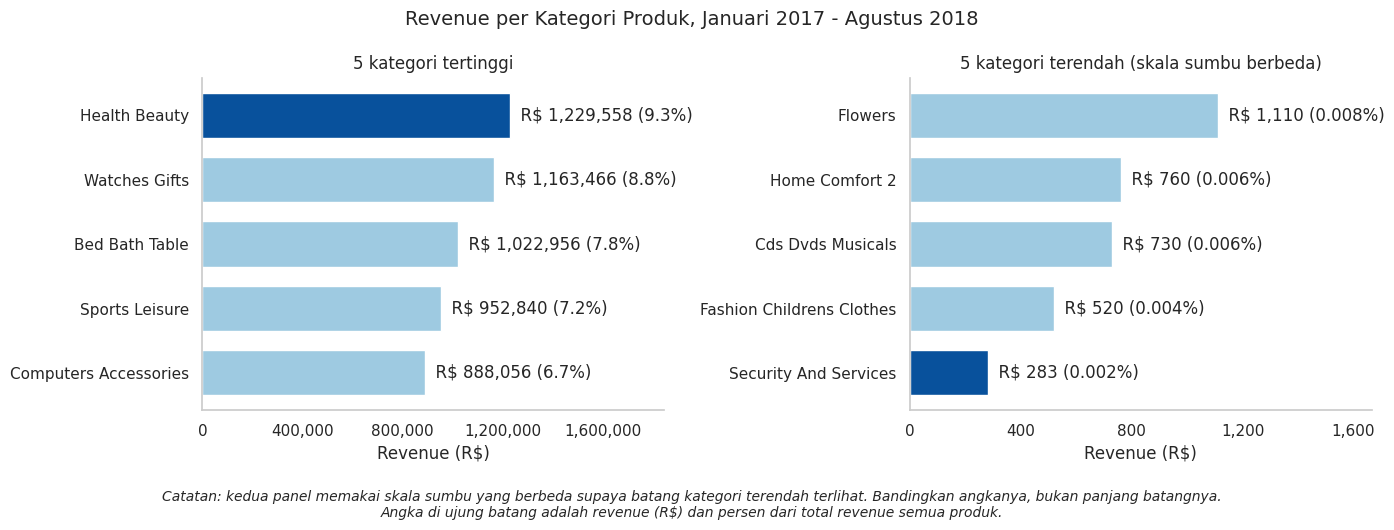

In [24]:
import matplotlib.ticker as mticker

top5 = kategori_df.head(5)
bottom5 = kategori_df.tail(5)

def format_persen(nilai):
    # persen yang sangat kecil diberi 3 desimal supaya tidak terbaca 0.0%
    return f'{nilai:.1f}%' if nilai >= 0.1 else f'{nilai:.3f}%'

def panel_kategori(ax, data, judul, sorot_terakhir):
    # satu panel = satu sumbu. Biru tua menyorot yang paling ekstrem di panel itu.
    warna = ['#9ecae1'] * len(data)
    warna[-1 if sorot_terakhir else 0] = '#08519c'
    ax.barh(range(len(data)), data['revenue'], color=warna, height=0.7)
    ax.set_yticks(range(len(data)))
    ax.set_yticklabels(data['category'])
    ax.invert_yaxis()  # urutan dari revenue terbesar di atas
    for i, (rev, pct) in enumerate(zip(data['revenue'], data['kontribusi_persen'])):
        ax.text(rev, i, f'  R$ {rev:,.0f} ({format_persen(pct)})', va='center')
    ax.set_xlim(0, data['revenue'].max() * 1.5)  # ruang untuk label angka
    ax.set_title(judul)
    ax.set_xlabel('Revenue (R$)')
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.grid(False)  # nilai sudah ditulis di ujung batang, gridline tidak perlu

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
panel_kategori(axes[0], top5, '5 kategori tertinggi', sorot_terakhir=False)
panel_kategori(axes[1], bottom5, '5 kategori terendah (skala sumbu berbeda)', sorot_terakhir=True)
sns.despine(fig=fig)
plt.suptitle('Revenue per Kategori Produk, Januari 2017 - Agustus 2018', fontsize=14)
plt.figtext(0.5, -0.02, 'Catatan: kedua panel memakai skala sumbu yang berbeda supaya batang kategori terendah terlihat. Bandingkan angkanya, bukan panjang batangnya.\n'
            'Angka di ujung batang adalah revenue (R$) dan persen dari total revenue semua produk.',
            ha='center', va='top', fontsize=10, style='italic')
plt.tight_layout()
plt.show()


**Insight:**
- Health Beauty tertinggi (R\$ 1.23 juta, 9.3%), disusul Watches Gifts (8.8%), Bed Bath Table (7.8%), Sports Leisure (7.2%), dan Computers Accessories (6.7%). Selisih kelimanya kecil, jadi tidak ada satu kategori yang mendominasi. Bersama-sama mereka 39.9% dari revenue yang tersebar di 73 kategori.
- Lima kategori terendah (Flowers, Home Comfort 2, Cds Dvds Musicals, Fashion Childrens Clothes, Security And Services) masing-masing di bawah R\$ 1,200. Totalnya 0.03%, jadi kalau kategori-kategori ini hilang, revenue hampir tidak berubah. Di grafik, kedua kelompok memakai skala sumbu yang berbeda supaya batang kategori terendah terlihat, jadi bandingkan angkanya, bukan panjang batangnya. Selisihnya besar: revenue Health Beauty sekitar 1,100 kali revenue Flowers.
- Persentase dihitung dari seluruh revenue, termasuk produk tanpa kategori (1.29%).
- Data ini tidak memuat margin, stok, atau jumlah produk per kategori. Yang bisa dikatakan hanya bahwa revenue terbesar ada di lima kategori itu, bukan bahwa mereka paling menguntungkan. Lima besar masuk akal jadi prioritas awal untuk stok dan promosi. Kategori terbawah perlu dicek dulu (produk baru atau memang tidak laku) sebelum stoknya dikurangi.

### Pertanyaan 2: Tren pesanan dan revenue per bulan

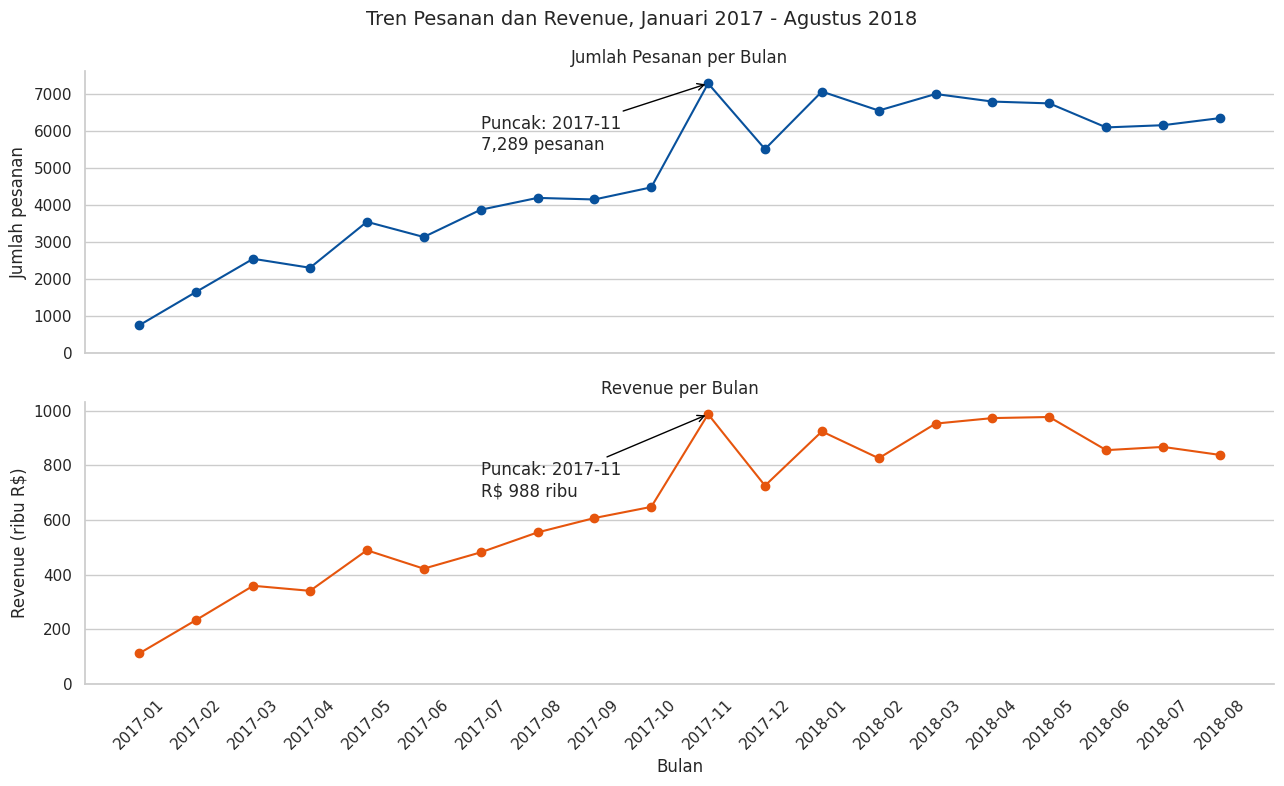

In [25]:
label = bulanan_df['bulan'].astype(str)
puncak = bulanan_df['jumlah_order'].idxmax()

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(label, bulanan_df['jumlah_order'], marker='o', color='#08519c')
axes[0].set_title('Jumlah Pesanan per Bulan')
axes[0].set_ylabel('Jumlah pesanan')
axes[0].annotate(
    f"Puncak: {label[puncak]}\n{bulanan_df.loc[puncak, 'jumlah_order']:,} pesanan",
    xy=(puncak, bulanan_df.loc[puncak, 'jumlah_order']),
    xytext=(puncak - 4, bulanan_df.loc[puncak, 'jumlah_order'] - 1800),
    arrowprops=dict(arrowstyle='->', color='black'),
)

axes[1].plot(label, bulanan_df['revenue'] / 1e3, marker='o', color='#e6550d')
puncak_rev = bulanan_df['revenue'].idxmax()
axes[1].annotate(
    f"Puncak: {label[puncak_rev]}\nR$ {bulanan_df.loc[puncak_rev, 'revenue'] / 1e3:,.0f} ribu",
    xy=(puncak_rev, bulanan_df.loc[puncak_rev, 'revenue'] / 1e3),
    xytext=(puncak_rev - 4, bulanan_df.loc[puncak_rev, 'revenue'] / 1e3 - 300),
    arrowprops=dict(arrowstyle='->', color='black'),
)
axes[1].set_title('Revenue per Bulan')
axes[1].set_ylabel('Revenue (ribu R$)')
axes[1].set_xlabel('Bulan')
axes[1].tick_params(axis='x', rotation=45)

for ax in axes:
    ax.set_ylim(bottom=0)
    ax.grid(axis='x', visible=False)
sns.despine(fig=fig)

plt.suptitle('Tren Pesanan dan Revenue, Januari 2017 - Agustus 2018', fontsize=14)
plt.tight_layout()
plt.show()

#### Pertumbuhan Month-over-Month (MoM)

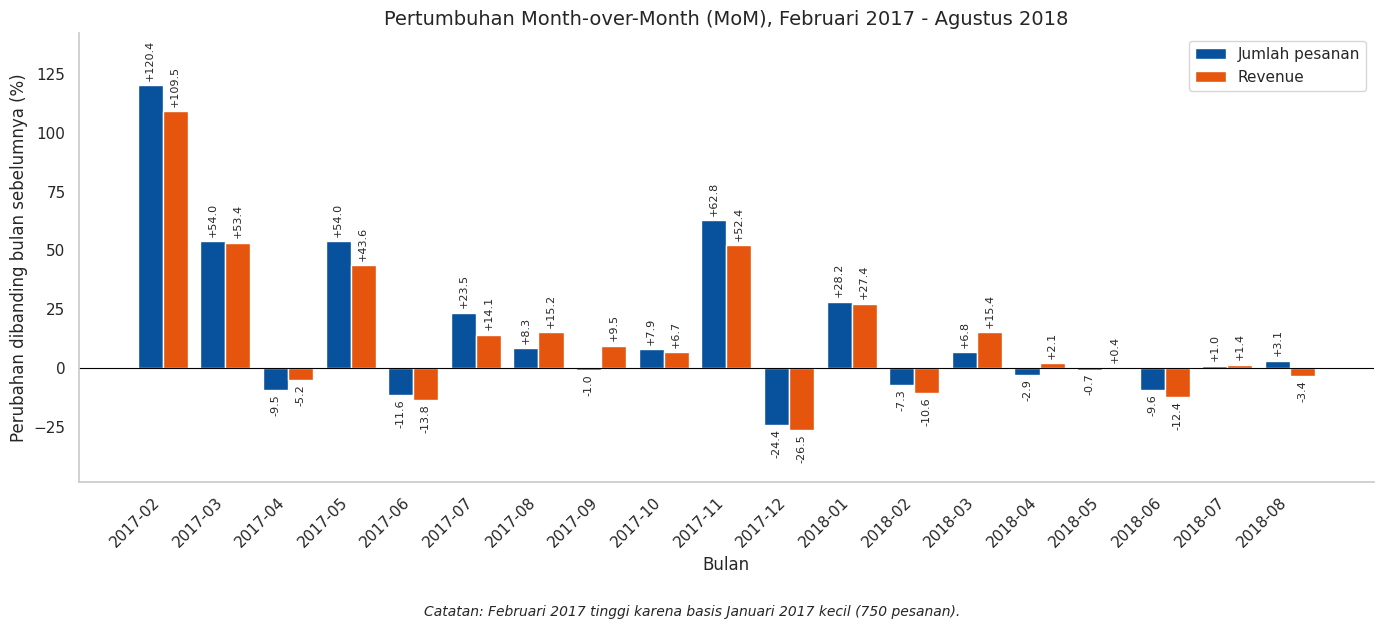

In [26]:
mom_df = bulanan_df.iloc[1:].copy()
label_mom = mom_df['bulan'].astype(str)
posisi = np.arange(len(mom_df))
lebar = 0.4

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(posisi - lebar / 2, mom_df['mom_order_persen'], lebar, label='Jumlah pesanan', color='#08519c')
ax.bar(posisi + lebar / 2, mom_df['mom_revenue_persen'], lebar, label='Revenue', color='#e6550d')
ax.axhline(0, color='black', linewidth=0.8)

# label nilai di setiap batang, supaya batang yang nyaris nol (misalnya Mei 2018) tetap terbaca
for geser, kolom in [(-lebar / 2, 'mom_order_persen'), (lebar / 2, 'mom_revenue_persen')]:
    for x, nilai in zip(posisi + geser, mom_df[kolom]):
        ax.annotate(f'{nilai:+.1f}', (x, nilai), xytext=(0, 3 if nilai >= 0 else -3), textcoords='offset points',
                    ha='center', va='bottom' if nilai >= 0 else 'top', rotation=90, fontsize=8)
ax.margins(y=0.15)
ax.set_xticks(posisi)
ax.set_xticklabels(label_mom, rotation=45, ha='right')
ax.set_xlabel('Bulan')
ax.set_ylabel('Perubahan dibanding bulan sebelumnya (%)')
ax.set_title('Pertumbuhan Month-over-Month (MoM), Februari 2017 - Agustus 2018', fontsize=14)
ax.legend()
ax.grid(False)  # nilai sudah ditulis di setiap batang
sns.despine(fig=fig)
plt.figtext(0.5, -0.04, 'Catatan: Februari 2017 tinggi karena basis Januari 2017 kecil (750 pesanan).',
            ha='center', fontsize=10, style='italic')
plt.tight_layout()
plt.show()

**Insight:**
- Pesanan naik dari 750 (Januari 2017) ke 4,478 (Oktober 2017), dan revenue dari R\$ 112 ribu ke R\$ 648 ribu, walau sempat turun di April dan Juni (dan pesanan September -1.0%). Kenaikan persentase terbesar ada di Februari 2017 (+120.4% pesanan), tapi itu karena basis Januari kecil.
- Puncaknya November 2017: 7,289 pesanan dan R\$ 988 ribu, naik 62.8% dan 52.4% dari Oktober. Data tidak menyebut penyebabnya. Black Friday atau promo akhir tahun hanya dugaan.
- Desember turun 24.4% (pesanan) dan 26.5% (revenue), tapi sepanjang 2018 pesanan bertahan di 6,099 - 7,069 per bulan, mendekati level November (7,289). Jadi lonjakan November tidak hilang setelah Desember.
- Revenue 2018 tertinggi di Mei (R\$ 978 ribu), turun 12.4% di Juni, lalu R\$ 868 ribu di Juli dan R\$ 839 ribu di Agustus. Dari Mei ke Agustus pesanan turun 5.9% (6,749 ke 6,351), sedangkan revenue turun 14.2%. Revenue per pesanan turun dari sekitar R\$ 145 ke R\$ 132 (kolom `revenue_per_pesanan` di tabel EDA). Jadi pelemahan revenue lebih banyak datang dari nilai per pesanan yang mengecil daripada dari jumlah pesanan.
- Data tidak punya harga, promo, atau jenis produk per bulan, jadi penyebab penurunan nilai per pesanan belum bisa dipastikan. Hanya ada satu November di data, jadi pola lonjakan November juga baru satu kali teramati.

## Analisis Lanjutan (Opsional)

### RFM Analysis
Tujuan analisis ini adalah mengelompokkan customer berdasarkan kebiasaan belanjanya. RFM dihitung dari pesanan *delivered* Januari 2017 - Agustus 2018.
- **Recency:** berapa hari sejak belanja terakhir. Tanggal acuannya sehari setelah pesanan terakhir di data.
- **Frequency:** jumlah pesanan.
- **Monetary:** total belanja (jumlah `price`).

Recency dan Monetary diberi skor 1-4 dengan binning batas tetap (`pd.cut`, 4 paling bagus). Batasnya ditentukan manual karena `pd.cut` dengan 4 bin sama lebar tidak cocok untuk data ini: hampir semua customer jatuh ke bin pertama karena belanja tertinggi mencapai R\$ 13,440. Batas di bawah adalah asumsi analisis ini, bukan ketentuan dari pemilik bisnis:

| Skor | Recency (hari sejak belanja terakhir) | Monetary (total belanja) |
|---|---|---|
| 4 | 0 - 90 (sampai 3 bulan) | di atas R\$ 200 |
| 3 | 91 - 180 (3 sampai 6 bulan) | di atas R\$ 100 sampai R\$ 200 |
| 2 | 181 - 365 (6 sampai 12 bulan) | di atas R\$ 50 sampai R\$ 100 |
| 1 | di atas 365 (lebih dari 1 tahun) | sampai R\$ 50 |

Frequency tidak dibagi ke bin karena hampir semua customer cuma belanja sekali. Jadi dibedakan saja: sekali, atau dua kali ke atas. Segmennya dibuat dengan aturan manual (manual grouping):
- **Aktif** kalau skor Recency 3-4 (belanja terakhir dalam 180 hari), **Pasif** kalau 1-2.
- **Belanja Besar** kalau skor Monetary 3-4 (total belanja di atas R\$ 100), **Belanja Kecil** kalau 1-2.
- **Setia** kalau pernah belanja dua kali atau lebih. Setia dihitung lebih dulu, jadi customer Setia tidak ikut segmen Belanja Besar atau Belanja Kecil. Dua segmen itu hanya berisi customer yang belanja sekali.

In [27]:
tanggal_acuan = main_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = main_df.groupby('customer_unique_id').agg(
    terakhir_beli=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'nunique'),
    monetary=('price', 'sum'),
).reset_index()
rfm_df['recency'] = (tanggal_acuan - rfm_df['terakhir_beli']).dt.days

# binning dengan batas tetap (pd.cut), skor 4 = paling bagus
batas_recency = [0, 90, 180, 365, np.inf]   # hari sejak belanja terakhir
batas_monetary = [0, 50, 100, 200, np.inf]  # total belanja (R$)
rfm_df['r_score'] = pd.cut(rfm_df['recency'], bins=batas_recency, labels=[4, 3, 2, 1], include_lowest=True).astype(int)
rfm_df['m_score'] = pd.cut(rfm_df['monetary'], bins=batas_monetary, labels=[1, 2, 3, 4], include_lowest=True).astype(int)

rfm_df[['recency', 'frequency', 'monetary']].describe()

,recency,frequency,monetary
count,93104.000000,93104.000000,93104.000000
mean,236.702924,1.033371,141.573156
std,150.942219,0.209012,215.760366
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,218.000000,1.000000,89.700000
75%,345.000000,1.000000,154.175000
max,602.000000,15.000000,13440.000000


In [28]:
kondisi = [
    (rfm_df['frequency'] >= 2) & (rfm_df['r_score'] >= 3),
    (rfm_df['frequency'] >= 2) & (rfm_df['r_score'] < 3),
    (rfm_df['r_score'] >= 3) & (rfm_df['m_score'] >= 3),
    (rfm_df['r_score'] >= 3) & (rfm_df['m_score'] < 3),
    (rfm_df['m_score'] >= 3),
]
nama_segmen = ['Setia Aktif', 'Setia Pasif', 'Aktif Belanja Besar',
               'Aktif Belanja Kecil', 'Pasif Belanja Besar']
rfm_df['segmen'] = np.select(kondisi, nama_segmen, default='Pasif Belanja Kecil')

segmen_df = rfm_df.groupby('segmen').agg(
    jumlah_customer=('customer_unique_id', 'count'),
    total_revenue=('monetary', 'sum'),
    rata_rata_recency=('recency', 'mean'),
    rata_rata_monetary=('monetary', 'mean'),
).sort_values('jumlah_customer', ascending=False).reset_index()
segmen_df['persen_customer'] = segmen_df['jumlah_customer'] / segmen_df['jumlah_customer'].sum() * 100
segmen_df['persen_revenue'] = segmen_df['total_revenue'] / segmen_df['total_revenue'].sum() * 100

setia = segmen_df[segmen_df['segmen'].str.startswith('Setia')]
besar = segmen_df[segmen_df['segmen'].str.contains('Besar')]
kecil = segmen_df[segmen_df['segmen'].str.contains('Kecil')]
pasif = segmen_df[segmen_df['segmen'].isin(['Pasif Belanja Kecil', 'Pasif Belanja Besar', 'Setia Pasif'])]

print('Customer Setia          : {:,} customer ({:.1f}%), {:.1f}% revenue'.format(
    setia['jumlah_customer'].sum(), setia['persen_customer'].sum(), setia['persen_revenue'].sum()))
print('Revenue dari yang belanja sekali: {:.1f}%'.format(100 - setia['persen_revenue'].sum()))
print('Customer Belanja Besar (tanpa Setia): {:.1f}% customer, {:.1f}% revenue'.format(
    besar['persen_customer'].sum(), besar['persen_revenue'].sum()))
print('Rata-rata belanja Besar vs Kecil (tanpa Setia): R$ {:.1f} vs R$ {:.1f} ({:.1f}x)'.format(
    besar['total_revenue'].sum() / besar['jumlah_customer'].sum(),
    kecil['total_revenue'].sum() / kecil['jumlah_customer'].sum(),
    (besar['total_revenue'].sum() / besar['jumlah_customer'].sum()) / (kecil['total_revenue'].sum() / kecil['jumlah_customer'].sum())))
print('Revenue dari customer Pasif (semua): {:.1f}%'.format(pasif['persen_revenue'].sum()))
print()

segmen_df.round(1)

Customer Setia          : 2,789 customer (3.0%), 5.5% revenue
Revenue dari yang belanja sekali: 94.5%
Customer Belanja Besar (tanpa Setia): 40.2% customer, 73.1% revenue
Rata-rata belanja Besar vs Kecil (tanpa Setia): R$ 257.3 vs R$ 53.4 (4.8x)
Revenue dari customer Pasif (semua): 58.2%



,segmen,jumlah_customer,total_revenue,rata_rata_recency,rata_rata_monetary,persen_customer,persen_revenue
0,Pasif Belanja Kecil,31845,1706663.3,337.9,53.6,34.2,12.9
1,Pasif Belanja Besar,21595,5576604.9,336.5,258.2,23.2,42.3
2,Aktif Belanja Kecil,21031,1114450.2,91.3,53.0,22.6,8.5
3,Aktif Belanja Besar,15844,4057953.7,93.3,256.1,17.0,30.8
4,Setia Pasif,1558,394079.2,321.2,252.9,1.7,3.0
5,Setia Aktif,1231,331275.8,91.0,269.1,1.3,2.5


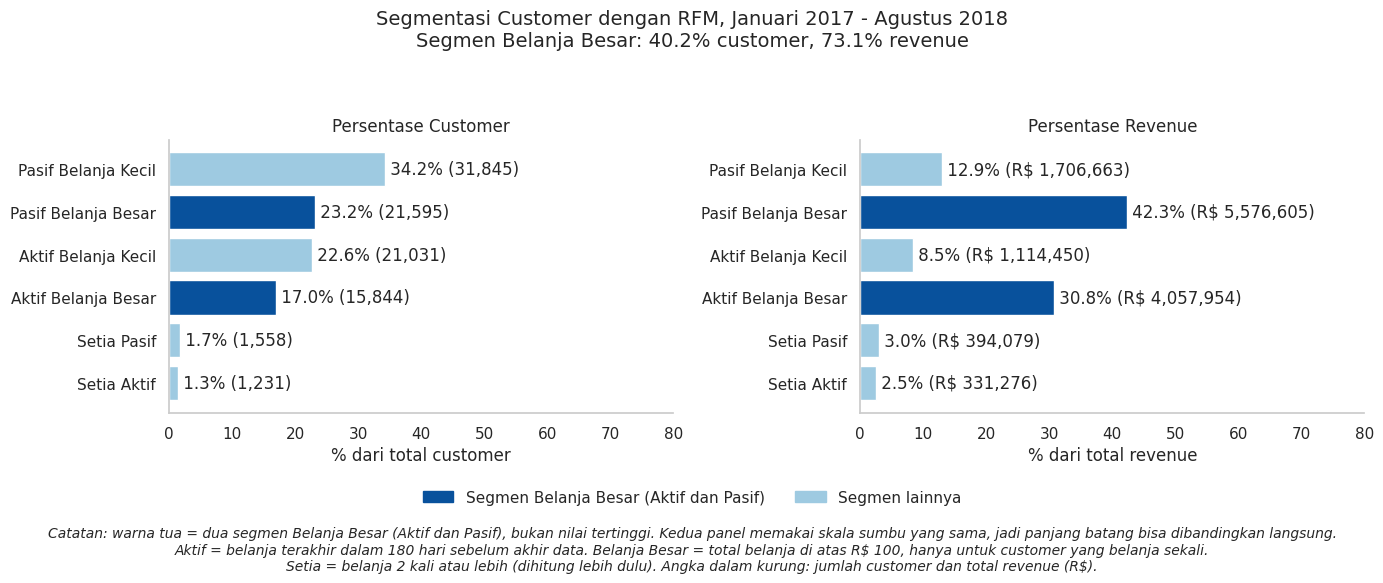

In [29]:
urut = segmen_df.sort_values('jumlah_customer')
besar = urut[urut['segmen'].str.contains('Besar')]

# segmen Belanja Besar disorot dengan warna tua, segmen lain dengan warna muda
warna_segmen = ['#08519c' if 'Besar' in s else '#9ecae1' for s in urut['segmen']]

# kedua panel memakai skala sumbu yang sama supaya panjang batang bisa dibandingkan
batas = max(urut['persen_customer'].max(), urut['persen_revenue'].max()) * 1.75  # ruang untuk label angka
# label: persen, lalu angka aslinya dalam kurung
label_customer = [f' {p:.1f}% ({n:,})' for p, n in zip(urut['persen_customer'], urut['jumlah_customer'])]
label_revenue = [f' {p:.1f}% (R$ {r:,.0f})' for p, r in zip(urut['persen_revenue'], urut['total_revenue'])]

# tidak memakai sharey: nama segmen tampil di kedua panel
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
panel_rfm = [
    (axes[0], 'persen_customer', label_customer, 'Persentase Customer', '% dari total customer'),
    (axes[1], 'persen_revenue', label_revenue, 'Persentase Revenue', '% dari total revenue'),
]
for ax, kolom, label, judul, label_x in panel_rfm:
    ax.barh(urut['segmen'], urut[kolom], color=warna_segmen)
    for i, teks in enumerate(label):
        ax.text(urut[kolom].iloc[i], i, teks, va='center')
    ax.set_title(judul)
    ax.set_xlabel(label_x)
    ax.set_xlim(0, batas)
    ax.set_xticks([t for t in ax.get_xticks() if 0 <= t <= 100])  # sumbu persen tidak boleh menunjukkan angka di atas 100
    ax.grid(False)  # nilai sudah ditulis di ujung batang, gridline tidak perlu
sns.despine(fig=fig)

# legenda arti warna di dalam grafik
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='#08519c', label='Segmen Belanja Besar (Aktif dan Pasif)'),
                    Patch(color='#9ecae1', label='Segmen lainnya')],
           loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0))

plt.suptitle('Segmentasi Customer dengan RFM, Januari 2017 - Agustus 2018\n'
             f'Segmen Belanja Besar: {besar["persen_customer"].sum():.1f}% customer, {besar["persen_revenue"].sum():.1f}% revenue', fontsize=14)
plt.figtext(0.5, -0.015, 'Catatan: warna tua = dua segmen Belanja Besar (Aktif dan Pasif), bukan nilai tertinggi. Kedua panel memakai skala sumbu yang sama, jadi panjang batang bisa dibandingkan langsung.\n'
            'Aktif = belanja terakhir dalam 180 hari sebelum akhir data. Belanja Besar = total belanja di atas R$ 100, hanya untuk customer yang belanja sekali.\n'
            'Setia = belanja 2 kali atau lebih (dihitung lebih dulu). Angka dalam kurung: jumlah customer dan total revenue (R$).',
            ha='center', va='top', fontsize=10, style='italic')
plt.tight_layout(rect=[0, 0.07, 1, 0.92])
plt.show()


**Insight:**
- Hanya 2,789 dari 93,104 customer (3.0%) yang belanja lebih dari sekali, dan mereka menyumbang 5.5% revenue. Sekitar 94.5% revenue datang dari customer yang belanja satu kali. Rata-rata belanja customer Setia R\$ 253 - 269, setara dengan customer Belanja Besar (R\$ 256 - 258).
- Dengan batas Monetary R\$ 100, customer Belanja Besar (di luar customer Setia) adalah 40.2% customer tapi menyumbang 73.1% revenue. Rata-rata belanja mereka R\$ 257 per customer, sekitar 4.8 kali Belanja Kecil (R\$ 53).
- Dengan batas Recency 180 hari, 59.1% customer (54,998 orang) berstatus Pasif, dengan rata-rata recency 321 - 338 hari. Mereka menyumbang 58.2% revenue, jadi lebih dari separuh revenue berasal dari orang yang terakhir belanja lebih dari enam bulan sebelum akhir data. Rata-rata recency customer Aktif hanya 91 - 93 hari. Angka ini bergantung pada batas 180 hari, yang merupakan asumsi analisis ini.
- Pasif Belanja Besar adalah segmen dengan kontribusi revenue terbesar: 21,595 customer (23.2%) dan 42.3% revenue, dengan rata-rata belanja R\$ 258. Aktif Belanja Besar lebih kecil: 15,844 customer (17.0%) dan 30.8% revenue.
- Karena hampir semua customer belanja sekali, retensi adalah titik lemahnya. Segmen yang paling masuk akal didekati dulu adalah Pasif Belanja Besar. Data ini tidak menunjukkan apakah mereka akan merespons voucher atau email, jadi hasilnya perlu diukur.

#### Customer Terbaik per Parameter RFM
Selain segmentasi, kita lihat 5 customer terbaik untuk tiap parameter: Recency terkecil, Frequency terbanyak, dan Monetary terbesar. Kalau nilainya seri, dipilih customer yang total belanjanya lebih besar.

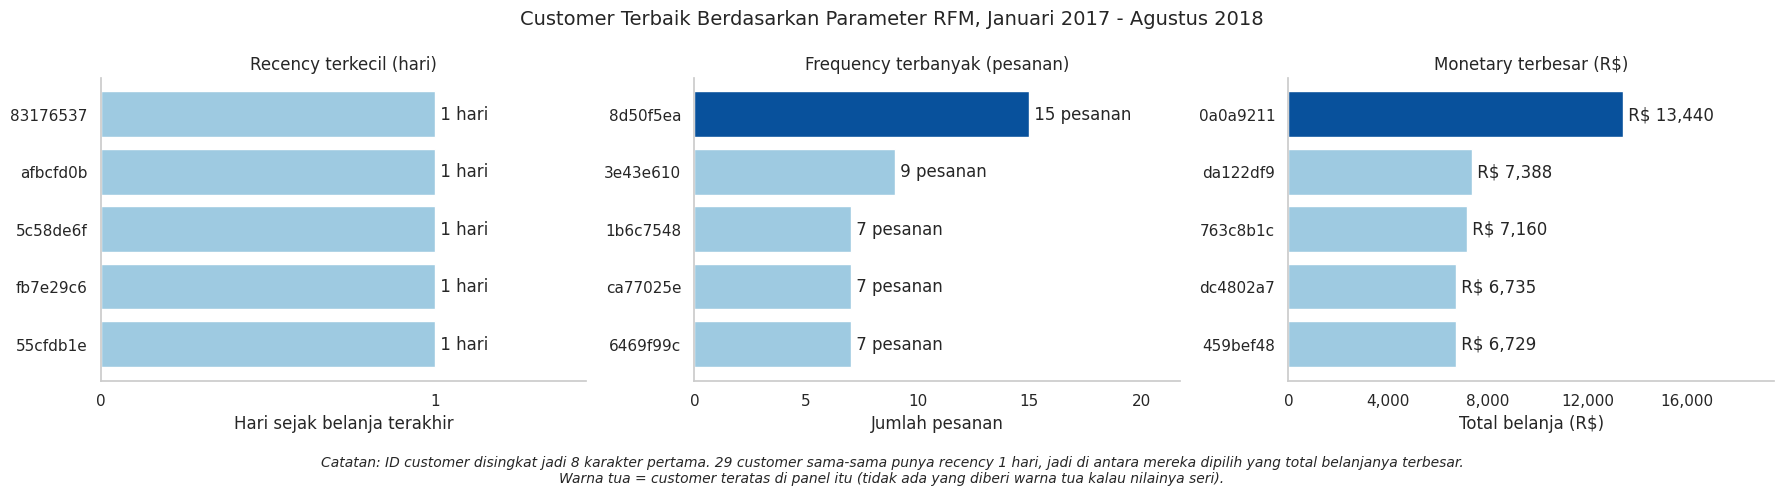

Customer dengan recency 1 hari: 29
Customer dengan frequency 15 pesanan: 1
Customer yang masuk lebih dari satu daftar: 0
Rata-rata frequency: 1.03 pesanan | rata-rata monetary: R$ 141.6


In [30]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

# 5 customer terbaik untuk tiap parameter RFM.
# Kalau nilainya seri, dipilih customer yang total belanjanya lebih besar.
top_recency = rfm_df.sort_values(['recency', 'monetary'], ascending=[True, False]).head(5)
top_frequency = rfm_df.sort_values(['frequency', 'monetary'], ascending=[False, False]).head(5)
top_monetary = rfm_df.sort_values('monetary', ascending=False).head(5)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
panel = [
    (axes[0], top_recency, 'recency', 'Recency terkecil (hari)', lambda v: f' {v:,.0f} hari', 'Hari sejak belanja terakhir'),
    (axes[1], top_frequency, 'frequency', 'Frequency terbanyak (pesanan)', lambda v: f' {v:,.0f} pesanan', 'Jumlah pesanan'),
    (axes[2], top_monetary, 'monetary', 'Monetary terbesar (R$)', lambda v: f' R$ {v:,.0f}', 'Total belanja (R$)'),
]
for ax, data, kolom, judul, format_label, label_x in panel:
    data = data.iloc[::-1]  # customer terbaik ada di paling atas
    warna = ['#9ecae1'] * (len(data) - 1) + ['#08519c']
    if len(data) > 1 and data[kolom].iloc[-1] == data[kolom].iloc[-2]:
        warna = ['#9ecae1'] * len(data)  # posisi teratas seri, jadi tidak ada yang disorot
    ax.barh(data['customer_unique_id'].str[:8], data[kolom], color=warna)
    for i, nilai in enumerate(data[kolom]):
        ax.text(nilai, i, format_label(nilai), va='center')
    ax.set_xlim(0, data[kolom].max() * 1.45)  # ruang untuk label angka
    ax.set_title(judul)
    ax.set_xlabel(label_x)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.grid(False)  # nilai sudah ditulis di ujung batang
sns.despine(fig=fig)

n_seri = (rfm_df['recency'] == rfm_df['recency'].min()).sum()
fig.suptitle('Customer Terbaik Berdasarkan Parameter RFM, Januari 2017 - Agustus 2018', fontsize=14)
fig.text(0.5, -0.01,
         f'Catatan: ID customer disingkat jadi 8 karakter pertama. {n_seri:,} customer sama-sama punya recency '
         f'{rfm_df["recency"].min()} hari, jadi di antara mereka dipilih yang total belanjanya terbesar.\n'
         'Warna tua = customer teratas di panel itu (tidak ada yang diberi warna tua kalau nilainya seri).',
         ha='center', va='top', fontsize=10, style='italic')
plt.tight_layout()
plt.show()

jumlah_daftar = pd.concat([top_recency, top_frequency, top_monetary])['customer_unique_id'].value_counts()
print('Customer dengan recency {} hari: {:,}'.format(rfm_df['recency'].min(), n_seri))
print('Customer dengan frequency {} pesanan: {:,}'.format(rfm_df['frequency'].max(), (rfm_df['frequency'] == rfm_df['frequency'].max()).sum()))
print('Customer yang masuk lebih dari satu daftar:', int((jumlah_daftar > 1).sum()))
print('Rata-rata frequency: {:.2f} pesanan | rata-rata monetary: R$ {:.1f}'.format(rfm_df['frequency'].mean(), rfm_df['monetary'].mean()))

**Insight:**
- Monetary: 5 customer dengan belanja terbesar menghabiskan R\$ 6,729 sampai R\$ 13,440. Rata-rata semua customer hanya R\$ 141.6.
- Frequency: paling banyak 15 pesanan (hanya 1 customer), lalu 9 dan 7 pesanan. Rata-rata semua customer hanya 1.03 pesanan.
- Recency: 29 customer sama-sama belanja di hari terakhir data (1 hari). Karena seri, grafik Recency tidak bisa menunjuk satu customer paling baru. Yang dipilih adalah yang belanjanya terbesar.
- Tidak ada customer yang masuk lebih dari satu daftar. Jadi customer yang paling sering belanja belum tentu yang total belanjanya terbesar.

### Geospatial Analysis
Tujuan analisis ini adalah melihat dari wilayah mana revenue paling banyak datang, dan apakah besarnya revenue sebuah wilayah berasal dari jumlah customer atau dari belanja per customer. Cakupannya sama dengan pertanyaan bisnis: pesanan *delivered*, Januari 2017 - Agustus 2018. Hasilnya dipakai untuk rekomendasi promo wilayah.

Lokasi customer diambil dari kode pos. Ada dua peta:
- **Peta hexbin (matplotlib)** per kode pos, di sel pertama. Wilayah Brasil dibagi menjadi sel heksagon, dan warna tiap sel menunjukkan jumlah revenue dari semua kode pos di dalamnya, supaya kode pos yang bertumpuk di kota besar (SP, RJ, MG) tidak saling menutupi. Warna memakai skala log karena selisih revenue antar wilayah besar. Di sebelahnya ada grafik batang revenue per negara bagian. Peta ini berupa gambar statis, jadi selalu tampil di notebook.
- **Peta interaktif (folium)** per negara bagian, di sub-bagian berikutnya. Peta ini bisa di-zoom dan setiap lingkaran punya popup berisi revenue, jumlah customer, dan revenue per customer, yang dipakai untuk membandingkan jumlah customer dengan belanja per customer.

In [31]:
state_df = main_df.groupby('customer_state').agg(
    revenue=('price', 'sum'),
    jumlah_customer=('customer_unique_id', 'nunique'),
    lat=('customer_lat', 'mean'),
    lng=('customer_lng', 'mean'),
).sort_values('revenue', ascending=False).reset_index()
state_df['persen_revenue'] = state_df['revenue'] / state_df['revenue'].sum() * 100

state_df['persen_customer'] = state_df['jumlah_customer'] / main_df['customer_unique_id'].nunique() * 100
state_df['revenue_per_customer'] = state_df['revenue'] / state_df['jumlah_customer']

print('Rata-rata revenue per customer (nasional): R$ {:.1f}'.format(main_df['price'].sum() / main_df['customer_unique_id'].nunique()))
print()
print('3 negara bagian teratas (SP, RJ, MG): {:.1f}% revenue'.format(state_df['persen_revenue'].head(3).sum()))
print('10 negara bagian teratas            : {:.1f}% revenue'.format(state_df['persen_revenue'].head(10).sum()))
print()

state_df.head(10).round(2)

Rata-rata revenue per customer (nasional): R$ 141.6

3 negara bagian teratas (SP, RJ, MG): 63.4% revenue
10 negara bagian teratas            : 87.9% revenue



,customer_state,revenue,jumlah_customer,lat,lng,persen_revenue,persen_customer,revenue_per_customer
0,SP,5055587.13,39065,-23.17,-47.05,38.36,41.96,129.41
1,RJ,1751433.85,11879,-22.76,-43.18,13.29,12.76,147.44
2,MG,1548206.88,10969,-19.92,-44.43,11.75,11.78,141.14
3,RS,726373.92,5151,-29.71,-51.96,5.51,5.53,141.02
4,PR,664048.00,4750,-24.81,-50.79,5.04,5.10,139.80
5,SC,504774.07,3441,-27.25,-49.57,3.83,3.70,146.69
6,BA,493339.26,3155,-13.03,-39.48,3.74,3.39,156.37
7,DF,295454.64,2013,-15.81,-47.98,2.24,2.16,146.77
8,GO,281932.21,1889,-16.61,-49.33,2.14,2.03,149.25
9,ES,267783.66,1925,-20.16,-40.48,2.03,2.07,139.11


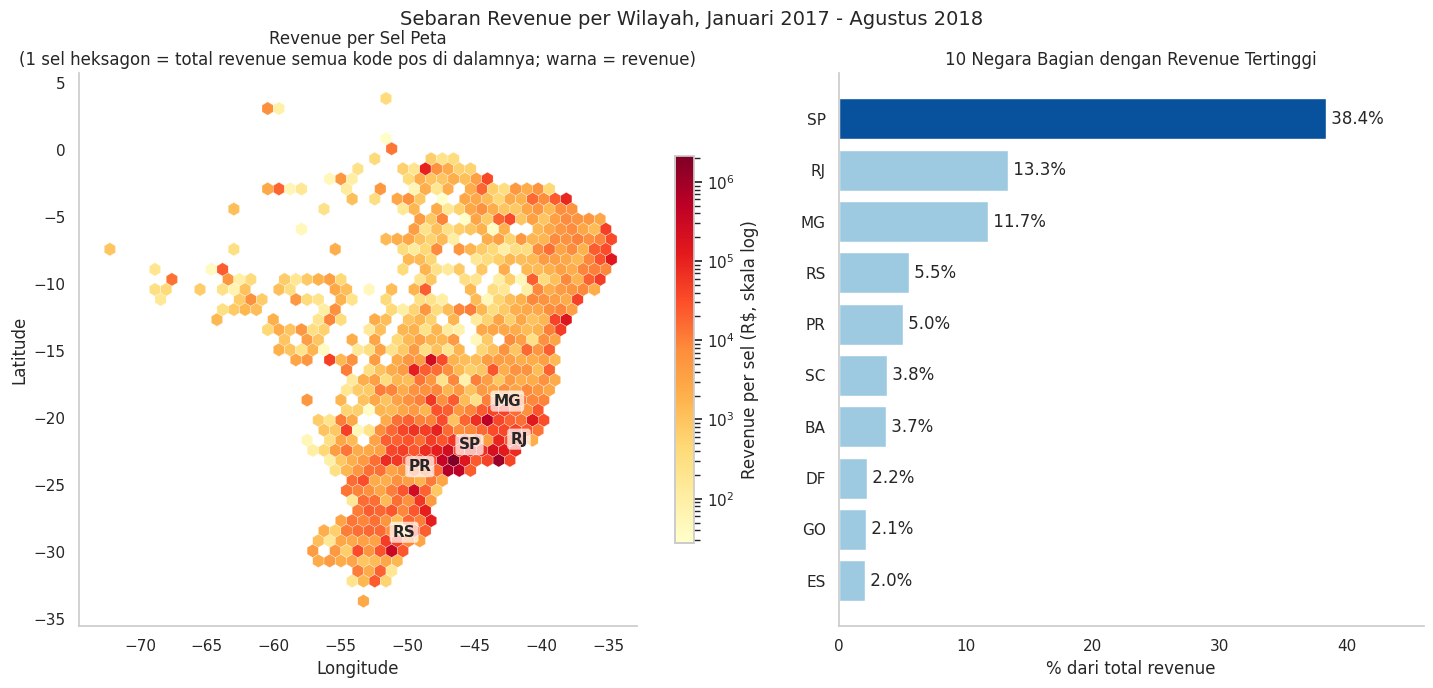

In [32]:
zip_df = (
    main_df.dropna(subset=['customer_lat', 'customer_lng'])
    .groupby('customer_zip_code_prefix')
    .agg(revenue=('price', 'sum'), lat=('customer_lat', 'mean'), lng=('customer_lng', 'mean'))
    .sort_values('revenue')
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.3, 1]})

# satu sel heksagon menjumlahkan revenue semua kode pos di dalamnya, jadi titik yang bertumpuk
# di kota besar tidak saling menutupi. Hanya warna yang membawa revenue (tidak ada ukuran titik).
sebar = axes[0].hexbin(zip_df['lng'], zip_df['lat'], C=zip_df['revenue'], reduce_C_function=np.sum,
                       gridsize=45, mincnt=1, cmap='YlOrRd', edgecolors='white', linewidths=0.2)
nilai_sel = sebar.get_array()
sebar.set_norm(LogNorm(vmin=nilai_sel.min(), vmax=nilai_sel.max()))
for _, baris in state_df.head(5).iterrows():
    # label digeser sedikit supaya tidak menutupi sel di bawahnya
    axes[0].annotate(baris['customer_state'], (baris['lng'], baris['lat']), xytext=(8, 8), textcoords='offset points',
                     fontsize=11, fontweight='bold',
                     bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7, lw=0))
axes[0].set_title('Revenue per Sel Peta\n(1 sel heksagon = total revenue semua kode pos di dalamnya; warna = revenue)')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].set_aspect('equal')
axes[0].grid(False)  # kisi latar tidak perlu, warna sel sudah membawa informasi
bar_warna = plt.colorbar(sebar, ax=axes[0], shrink=0.7, label='Revenue per sel (R$, skala log)')
bar_warna.solids.set_alpha(1)

top10 = state_df.head(10).sort_values('revenue')
warna = ['#9ecae1'] * 9 + ['#08519c']
axes[1].barh(top10['customer_state'], top10['persen_revenue'], color=warna)
for i, nilai in enumerate(top10['persen_revenue']):
    axes[1].text(nilai, i, f' {nilai:.1f}%', va='center')
axes[1].set_title('10 Negara Bagian dengan Revenue Tertinggi')
axes[1].set_xlabel('% dari total revenue')
axes[1].set_xlim(0, top10['persen_revenue'].max() * 1.2)
axes[1].grid(False)  # nilai sudah ditulis di ujung batang
sns.despine(fig=fig)

plt.suptitle('Sebaran Revenue per Wilayah, Januari 2017 - Agustus 2018', fontsize=14)

plt.tight_layout()
plt.show()

**Insight:**
- SP menyumbang 38.4% revenue (R\$ 5.06 juta), RJ 13.3%, dan MG 11.7%. Ketiganya 63.4%, dan sepuluh negara bagian teratas 87.9%.
- Besarnya SP datang dari jumlah customer. SP berisi 42.0% customer tapi 38.4% revenue, dengan rata-rata R\$ 129 per customer. Di RJ, MG, RS, PR, dan SC rata-ratanya R\$ 140 - 147 (nasional R\$ 141.6). Belanja per customer di negara bagian lain itu justru lebih tinggi dari SP.
- RS, PR, dan SC menyumbang 5.5%, 5.0%, dan 3.8% revenue. Selisih dengan SP ada di jumlah customer, jadi menambah customer lebih relevan di sana daripada mendorong belanja per customer.
- Keterbatasan: peta memakai rata-rata koordinat tiap kode pos lalu menjumlahkan revenue per sel heksagon, jadi satu sel bisa memuat kode pos dari lebih dari satu kota, dan label negara bagian memakai rata-rata koordinat customer di negara bagian itu. Posisinya perkiraan. 289 baris tanpa koordinat tidak muncul di peta, tapi tetap masuk grafik batang.

#### Peta interaktif per negara bagian (folium)
Peta ini menampilkan revenue per negara bagian dengan folium, lengkap dengan jumlah customer dan revenue per customer di popup. Teknik yang dipakai:
- **Binning:** persen revenue tiap negara bagian dibagi ke 5 kelas dengan batas tetap memakai `pd.cut` (< 1%, 1 - 3%, 3 - 6%, 6 - 15%, >= 15%). Batas tetap dipilih karena SP (38.4%) membuat gradasi warna kontinu menjadikan 26 negara bagian lain tampak pucat semua.
- **Manual grouping:** negara bagian dengan kurang dari 1,000 customer ditandai *basis kecil*, karena revenue per customer-nya mudah bergeser oleh beberapa pesanan saja. Di peta, lingkaran basis kecil diberi garis tepi putus-putus.
- Semua lingkaran berukuran sama dan hanya warna yang membawa informasi kontribusi revenue. Posisi lingkaran adalah rata-rata koordinat customer di negara bagian itu, jadi hanya perkiraan. Klik lingkaran untuk melihat detailnya.

In [33]:
# binning: persen revenue dibagi ke 5 kelas dengan batas tetap (pd.cut)
batas_kelas = [0, 1, 3, 6, 15, 101]
label_kelas = ['< 1%', '1 - 3%', '3 - 6%', '6 - 15%', '>= 15%']
state_df['kelas'] = pd.cut(state_df['persen_revenue'], bins=batas_kelas, labels=label_kelas, right=False)

# manual grouping: basis customer kecil kalau kurang dari 1,000 customer
state_df['basis_kecil'] = state_df['jumlah_customer'] < 1000
rata_nasional = main_df['price'].sum() / main_df['customer_unique_id'].nunique()
state_df['selisih_vs_nasional'] = state_df['revenue_per_customer'] - rata_nasional

print('Rata-rata revenue per customer (nasional): R$ {:.1f}'.format(rata_nasional))
print('Negara bagian basis kecil (< 1,000 customer):', state_df['basis_kecil'].sum())
print('Revenue per customer tiap negara bagian (dari yang terendah):')
tabel_rpc = state_df[['customer_state', 'jumlah_customer', 'revenue_per_customer', 'basis_kecil']].sort_values('revenue_per_customer')
print(tabel_rpc.round(1).to_string(index=False))
print()

kelas_df = state_df.groupby('kelas', observed=False).agg(
    jumlah_negara_bagian=('customer_state', 'count'),
    persen_revenue=('persen_revenue', 'sum'),
    daftar=('customer_state', lambda x: ', '.join(x)),
).round(1)
kelas_df

Rata-rata revenue per customer (nasional): R$ 141.6
Negara bagian basis kecil (< 1,000 customer): 15
Revenue per customer tiap negara bagian (dari yang terendah):
customer_state  jumlah_customer  revenue_per_customer  basis_kecil
            SP            39065                 129.4        False
            ES             1925                 139.1        False
            PR             4750                 139.8        False
            RS             5151                 141.0        False
            MG            10969                 141.1        False
            SC             3441                 146.7        False
            DF             2013                 146.8        False
            RJ            11879                 147.4        False
            GO             1889                 149.2        False
            BA             3155                 156.4        False
            AM              140                 158.3         True
            PE             1545  

,jumlah_negara_bagian,persen_revenue,daftar
kelas,,,
< 1%,13,6.1,"MA, MS, PB, PI, RN, AL, SE, TO, RO, AM, AC, AP..."
1 - 3%,7,12.4,"DF, GO, ES, PE, CE, PA, MT"
3 - 6%,4,18.1,"RS, PR, SC, BA"
6 - 15%,2,25.0,"RJ, MG"
>= 15%,1,38.4,SP


In [34]:
warna_kelas = dict(zip(label_kelas, ['#ffffb2', '#fecc5c', '#fd8d3c', '#f03b20', '#bd0026']))

# Peta dasar CARTO memakai API key yang ditulis langsung di sini.
kunci_carto = 'cb1_53zh_1_e69810704b79cac8c18d7ef8'
if kunci_carto:
    peta = folium.Map(
        location=[-14.2, -51.9], zoom_start=4, control_scale=True,
        tiles='https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png?key=' + kunci_carto,
        attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
    )
else:
    print('CARTO_KEY belum diisi, jadi peta dasar tidak ditampilkan.')
    peta = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles=None, control_scale=True)

for _, baris in state_df.iterrows():
    catatan = '<br><i>Basis kecil (&lt; 1,000 customer), angka belum stabil.</i>' if baris['basis_kecil'] else ''
    popup_html = (
        f"<b>{baris['customer_state']}</b><br>"
        f"Revenue: R$ {baris['revenue']:,.0f} ({baris['persen_revenue']:.1f}% dari total)<br>"
        f"Customer: {baris['jumlah_customer']:,}<br>"
        f"Revenue per customer: R$ {baris['revenue_per_customer']:.1f}<br>"
        f"Dibanding rata-rata nasional (R$ {rata_nasional:.1f}): R$ {baris['selisih_vs_nasional']:+.1f}"
        + catatan
    )
    folium.CircleMarker(
        location=[baris['lat'], baris['lng']], radius=8,
        color='#333333', weight=2, dash_array='4 4' if baris['basis_kecil'] else None, fill=True, fill_color=warna_kelas[baris['kelas']], fill_opacity=0.9,
        tooltip=baris['customer_state'], popup=folium.Popup(popup_html, max_width=280),
    ).add_to(peta)

baris_legenda = ''.join(
    f'<div><span style="display:inline-block;width:12px;height:12px;background:{warna};border:1px solid #333333;margin-right:6px;"></span>{nama}</div>'
    for nama, warna in warna_kelas.items()
)
baris_basis = (
    '<div style="margin-top:4px;"><span style="display:inline-block;width:10px;height:10px;border:2px dashed #333333;'
    'border-radius:50%;margin-right:6px;"></span>Garis putus-putus: basis kecil<br>(&lt; 1,000 customer)</div>'
)
legenda = (
    '<div style="position:fixed;bottom:70px;left:25px;z-index:9999;background:white;padding:8px 10px;'
    'border:1px solid #999;border-radius:4px;font-size:12px;">'
    '<b>Kontribusi revenue<br>(% dari total)</b>' + baris_legenda + baris_basis +
    '<div style="margin-top:4px;color:#555;">Ukuran lingkaran sama,<br>hanya warna yang berbeda.</div></div>'
)
judul = (
    '<div style="position:fixed;top:10px;left:50%;transform:translateX(-50%);z-index:9999;background:white;'
    'padding:4px 10px;border:1px solid #999;border-radius:4px;font-size:14px;">'
    '<b>Revenue per Negara Bagian, Januari 2017 - Agustus 2018</b></div>'
)
peta.get_root().html.add_child(folium.Element(legenda + judul))

peta

**Insight:**
- SP sendirian di kelas >= 15% (38.4% revenue). RJ dan MG di kelas 6 - 15% (25.0% berdua), RS, PR, SC, dan BA di kelas 3 - 6% (18.1%), tujuh negara bagian di kelas 1 - 3% (12.4%), dan 13 negara bagian di bawah 1% (6.1% total).
- Dari 27 negara bagian, SP punya revenue per customer paling rendah (R\$ 129.4, rata-rata nasional R\$ 141.6), disusul ES (R\$ 139.1) dan PR (R\$ 139.8). Jadi besarnya SP datang dari jumlah customer (39,065), bukan dari belanja per customer.
- 15 negara bagian punya kurang dari 1,000 customer (basis kecil). Gabungannya hanya 6.6% customer dan 8.5% revenue, tapi revenue per customer semuanya di atas rata-rata nasional (R\$ 158.3 - R\$ 223.7, tertinggi PB). Karena basisnya kecil, angka ini bisa bergeser oleh sedikit pesanan, jadi belum bisa dibaca sebagai pasar yang pasti lebih menguntungkan.
- Di antara 12 negara bagian dengan 1,000 customer ke atas, 7 berada di atas rata-rata nasional. Tertinggi CE (R\$ 174.2) dan PE (R\$ 162.2), keduanya dengan kontribusi revenue 1 - 3%.
- Revenue di sini hanya menghitung harga produk tanpa ongkir, jadi tingginya belanja per customer bukan berasal dari ongkos kirim. Penyebab lain (jenis produk, harga, atau jumlah item per pesanan) tidak bisa dipastikan dari data ini.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Lima kategori dengan revenue tertinggi adalah Health Beauty (R\$ 1.23 juta, 9.3%), Watches Gifts (8.8%), Bed Bath Table (7.8%), Sports Leisure (7.2%), dan Computers Accessories (6.7%). Totalnya 39.9% dari revenue, dan tidak ada satu kategori yang mendominasi. Lima kategori terendah (Flowers, Home Comfort 2, Cds Dvds Musicals, Fashion Childrens Clothes, Security And Services) hanya 0.03%.
- **Conclusion pertanyaan 2:** Pesanan dan revenue naik sepanjang 2017, dari 750 pesanan (R\$ 112 ribu) di Januari ke puncaknya di November 2017 dengan 7,289 pesanan (R\$ 988 ribu), naik 62.8% untuk pesanan dan 52.4% untuk revenue dari Oktober. Desember turun, lalu di 2018 pesanan bertahan di 6,099 - 7,069 per bulan. Revenue tertinggi di 2018 ada di Mei (R\$ 978 ribu), lalu turun di Juni dan bertahan di sekitar R\$ 840 - 870 ribu sampai Agustus.

**Rekomendasi Action Item:**
- Jadikan lima kategori teratas (mulai dari Health Beauty) prioritas awal untuk stok dan promosi. Kategori terbawah dicek dulu, apakah produk baru atau memang tidak laku, sebelum stoknya dikurangi atau digabung ke paket bundling.
- Siapkan stok dan pengiriman sebelum November. Data hanya punya satu November, jadi pola ini perlu dicek lagi dengan data tahun berikutnya. Promo Desember bisa dicoba untuk meredam penurunannya.
- Selidiki turunnya revenue sejak Juni 2018. Dari Mei ke Agustus pesanan turun 5.9% tapi revenue 14.2%, jadi cek dulu rata-rata harga per item dan kategori yang dibeli.
- Dekati customer Pasif Belanja Besar (21,595 customer, 42.3% revenue, rata-rata belanja R\$ 258) dengan voucher atau email, dan ukur responsnya. Karena sekitar 97% customer belanja sekali, program belanja ulang untuk customer baru juga perlu.
- Di RS, PR, dan SC, fokuskan promo wilayah untuk menambah jumlah customer. Belanja per customer di sana sudah lebih tinggi dari SP.